In [2]:
# %load_ext autoreload
%reload_ext autoreload
%autoreload 2

In [18]:
#!/usr/bin/env python3

import gtsam
import gtsam_unstable
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
%matplotlib widget
import numpy as np
np.set_printoptions(linewidth=np.inf, suppress=True)
import copy
import time
from pathlib import Path
import open3d as o3d
from scipy.spatial import KDTree
from dataclasses import asdict
import yaml
import pickle

# Local imports
from common.customTypes import DecisionType
import common.fgHelpers as fgtools
from params.params import Params
from multiSession.SessionManager import SessionManager

from common.groundTruthLoader import GroundTruthLoader

policy_labels = {
    "NONE": "None",
    "DISTANCE": "Distance",
    "OVERLAP": "Overlap",
    "INLIER_RATIO": "Inlier Ratio",
    "INLIER_RMSE": "Inlier RMSE",
    "TWO_STEP_VALIDATION": "Two Step Val",
    "TWO_OPTION": "Two Option",
    "RELATIVE_COVARIANCE": "Rel Cov"
}

policy_colors = {
    "NONE": "C6",
    "DISTANCE": "C0",
    "OVERLAP": "C1",
    "INLIER_RATIO": "C2",
    "INLIER_RMSE": "C3",
    "TWO_STEP_VALIDATION": "C4",
    "TWO_OPTION": "C6",
    "RELATIVE_COVARIANCE": "C5"
}

# figure_directory = Path().home() / "Pictures/ICRA_2027"
figure_directory = Path().home() / "Pictures/MastersThesis"
ws_dir = Path().home() / "decision_policy_python"

In [4]:
import matplotlib.pyplot as plt

# -------------------------------------------------------------------
# IEEE Conference Formatting Config
# -------------------------------------------------------------------
# Single-column width = 3.5 inches; Full-width = 7.16 inches
# WIDTH_SINGLE = 3.5 # ICRA
WIDTH_SINGLE = 5.0 # Thesis
WIDTH_DOUBLE = 7.16

# Aspect ratio helper (e.g., 4:3 ratio -> height = width * 0.75)
HEIGHT_SINGLE = WIDTH_SINGLE * 0.75 
HEIGHT_DOUBLE = WIDTH_SINGLE * 1.00 
# For 3 stacked panels, set height proportionally (e.g., 1.1x–1.3x column width)
HEIGHT_TRIPLE = WIDTH_SINGLE * 1.25

pgf_with_rc_fonts = {
    # Match paper typography (IEEE uses Times / Times New Roman)
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    
    # Enable LaTeX math rendering
    "text.usetex": False,  # Set to True if you have full TeX distribution installed
    "pdf.fonttype": 42,    # Embed TrueType fonts so text renders as scalable vectors
    "ps.fonttype": 42,

    # Font sizes relative to IEEE standard body text (10 pt) / figure captions (8 pt)
    "font.size": 6,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "legend.fontsize": 6,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,

    # Line weights and spacing
    "lines.linewidth": 1.2,
    "lines.markersize": 4,
    "axes.linewidth": 0.8,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.3,
    
    # Tight margins so axes labels aren't clipped
    "figure.autolayout": True,
}

plt.rcParams.update(pgf_with_rc_fonts)

# Timing Comparison Between Dense and Approximate Marginalization

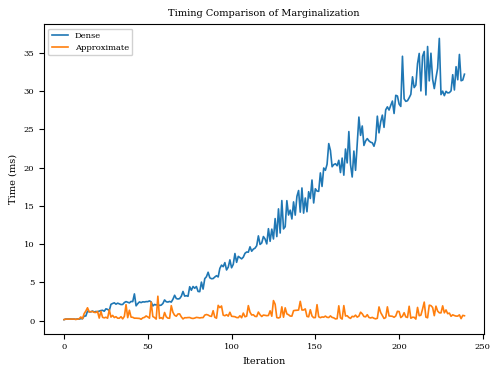

In [5]:
# Load timing pickle data and plot
timing_data_dense = np.loadtxt("../results/marginalizationEvaluation/nc/dense__quad-medium__quad-easy/DISTANCE/timeToOptimize.txt")
timing_data_approx = np.loadtxt("../results/marginalizationEvaluation/nc/approx__quad-medium__quad-easy/DISTANCE/timeToOptimize.txt")

# with open("../results/nc_tests/quad-medium_cov_current_pose_eval/update_timing_approx.pkl", "rb") as f:
#     timing_data_approx = pickle.load(f)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(WIDTH_SINGLE, HEIGHT_SINGLE))
ax.plot(timing_data_dense*1e3, label="Dense")
ax.plot(timing_data_approx*1e3, label="Approximate")
ax.set_xlabel("Iteration")
ax.set_ylabel("Time (ms)")
ax.set_title("Timing Comparison of Marginalization")
ax.legend(loc="upper left", frameon=True, framealpha=0.9)


# Comparison of Determinants of Covariance for Dense and Approximate Marginalizations

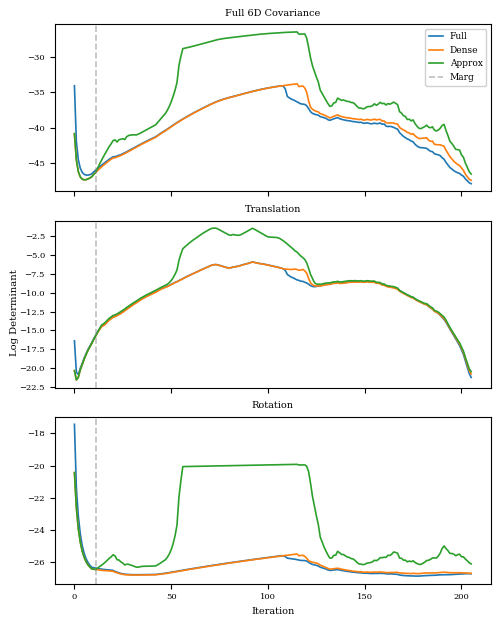

In [6]:
# Plot determinant of covariance matrices
plt.close("all")
with open("../results/marginalizationEvaluation/nc/fullSLAM__quad-hard__quad-easy/cov_of_currentPoses.pkl", "rb") as f:
    cov_data_slam = np.asarray(pickle.load(f))

with open("../results/marginalizationEvaluation/nc/dense__quad-hard__quad-easy/cov_of_currentPoses.pkl", "rb") as f:
    cov_data_dense = np.asarray(pickle.load(f))

with open("../results/marginalizationEvaluation/nc/approx__quad-hard__quad-easy/cov_of_currentPoses.pkl", "rb") as f:
    cov_data_approx = np.asarray(pickle.load(f))

det_full_slam = np.linalg.det(cov_data_slam)
det_full_dense = np.linalg.det(cov_data_dense)
det_full_approx = np.linalg.det(cov_data_approx)

det_trans_slam = np.linalg.det(cov_data_slam[:, 3:, 3:])
det_trans_dense = np.linalg.det(cov_data_dense[:, 3:, 3:])
det_trans_approx = np.linalg.det(cov_data_approx[:, 3:, 3:])

det_rot_slam = np.linalg.det(cov_data_slam[:, :3, :3])
det_rot_dense = np.linalg.det(cov_data_dense[:, :3, :3])
det_rot_approx = np.linalg.det(cov_data_approx[:, :3, :3])

det_slam = np.log([det_full_slam, det_trans_slam, det_rot_slam])
det_dense = np.log([det_full_dense, det_trans_dense, det_rot_dense])
det_approx = np.log([det_full_approx, det_trans_approx, det_rot_approx])

fig, ax = plt.subplots(3, 1, figsize=(WIDTH_SINGLE, HEIGHT_TRIPLE), sharex=True)
titles = ["Full 6D Covariance", "Translation", "Rotation"]

for i in range(3):
    # ax[i].set_yscale("log")
    ax[i].plot(det_slam[i], label="Full")
    ax[i].plot(det_dense[i], label="Dense")
    ax[i].plot(det_approx[i], label="Approx")
    ax[i].axvline(11, linestyle="--", color="tab:gray", alpha=0.5, label="Marg")
    ax[i].set_title(titles[i])
    if i == 2:
        ax[i].set_xlabel("Iteration")
    # ax[i].set_ylabel("Log Det")
    if i == 0:
        ax[i].legend(loc="upper right", frameon=True, framealpha=0.9, handlelength=1.5, fontsize=6.5)

fig.supylabel("Log Determinant")
# fig.supxlabel("Iterations")

# plt.suptitle("Determinant of Covariance Matrix of\n" + rf"Current Pose ($\mathcal{{V}}_l^t$)")
plt.tight_layout()
plt.show()

In [ ]:
# MUST use bbox_inches="tight" when saving, otherwise the legend off-canvas gets cropped out
# plt.savefig(figure_directory / "icra_cov_eval_dense_vs_approx.pdf", format="pdf", dpi=300, bbox_inches="tight")

Determinant is greater than 0 100.00% of the time
Is PSD 86.89% of the time


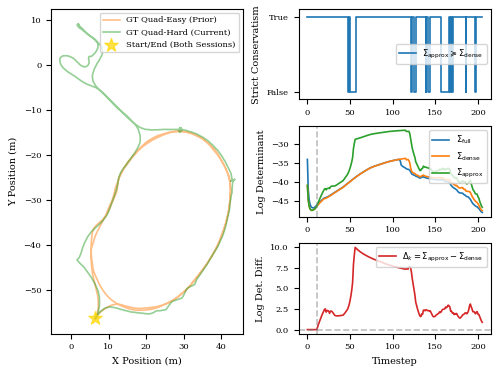

In [7]:
from common.groundTruthLoader import GroundTruthLoader

CURRENT_SESSION = "quad-hard"

# Plot determinant of covariance matrices
plt.close("all")
# Load covariance data for different SLAM approaches
slam_dir = f"../results/marginalizationEvaluation/nc/fullSLAM__{CURRENT_SESSION}__quad-easy/"
dense_dir = f"../results/marginalizationEvaluation/nc/dense__{CURRENT_SESSION}__quad-easy/"
approx_dir = f"../results/marginalizationEvaluation/nc/approx__{CURRENT_SESSION}__quad-easy/"

with open(slam_dir + "cov_of_currentPoses.pkl", "rb") as f:
    cov_data_slam = np.asarray(pickle.load(f))

with open(dense_dir + "cov_of_currentPoses.pkl", "rb") as f:
    cov_data_dense = np.asarray(pickle.load(f))

with open(approx_dir + "cov_of_currentPoses.pkl", "rb") as f:
    cov_data_approx = np.asarray(pickle.load(f))

det_full_slam = np.log(np.linalg.det(cov_data_slam))
det_full_dense = np.log(np.linalg.det(cov_data_dense))
det_full_approx = np.log(np.linalg.det(cov_data_approx))

# det_full_slam   = np.linalg.det(cov_data_slam)
# det_full_dense  = np.linalg.det(cov_data_dense)
# det_full_approx = np.linalg.det(cov_data_approx)

# det_diff = det_full_approx[11:] - det_full_dense[11:]
det_diff = det_full_approx - det_full_dense

det_above_zero = 100 * (len(det_diff[det_diff > -1e-9]) / len(det_diff))
print(f"Determinant is greater than 0 {det_above_zero:.2f}% of the time")

gt_NCE_dir = Path().home() / "data_sets/NewerCollege/ros2/ground_truth_tum/"

gt_easy = GroundTruthLoader(gt_NCE_dir / "gt-nc-quad-easy.csv", "NC")
gt_hard = GroundTruthLoader(gt_NCE_dir / f"gt-nc-{CURRENT_SESSION}.csv", "NC")

# det_trans_slam = np.linalg.det(cov_data_slam[:, 3:, 3:])
# det_trans_dense = np.linalg.det(cov_data_dense[:, 3:, 3:])
# det_trans_approx = np.linalg.det(cov_data_approx[:, 3:, 3:])

# det_rot_slam = np.linalg.det(cov_data_slam[:, :3, :3])
# det_rot_dense = np.linalg.det(cov_data_dense[:, :3, :3])
# det_rot_approx = np.linalg.det(cov_data_approx[:, :3, :3])

# det_slam = np.log([det_full_slam, det_trans_slam, det_rot_slam])
# det_dense = np.log([det_full_dense, det_trans_dense, det_rot_dense])
# det_approx = np.log([det_full_approx, det_trans_approx, det_rot_approx])

psd = []
for cov1, cov2 in zip(cov_data_approx, cov_data_dense):
    # cov1 = 
    
    # cov2 = d2["covariance"]
    psd.append(fgtools.isPSD(cov1 - cov2, printDebug=False))

print(f"Is PSD {sum(psd)/len(psd)*100:.2f}% of the time")


# fig, ax = plt.subplots(2, 1, figsize=(WIDTH_SINGLE, HEIGHT_SINGLE), sharex=True)
fig, ax = plt.subplot_mosaic([["left", "middle_right"], ["left", "top_right"], ["left", "bottom_right"]], figsize=(WIDTH_SINGLE, HEIGHT_SINGLE))
titles = ["Full 6D Covariance", "Translation", "Rotation"]

ax["left"].plot(gt_easy.array[:,1], gt_easy.array[:,2], color='tab:orange', label='GT Quad-Easy (Prior)',   alpha=0.5)
ax["left"].plot(gt_hard.array[:,1], gt_hard.array[:,2], color='tab:green',  label=f'GT {CURRENT_SESSION.title()} (Current)', alpha=0.5)
ax["left"].scatter(gt_easy.array[0,1], gt_easy.array[0,2], s=100, color='gold', marker='*', label='Start/End (Both Sessions)', alpha=0.7, zorder=2)
ax["left"].set_xlabel("X Position (m)")
ax["left"].set_ylabel("Y Position (m)")
if CURRENT_SESSION == "quad-medium":
    ax["left"].set_ylim(-59, -5)

# ax[i].set_yscale("log")
ax["top_right"].plot(det_full_slam, label=r"$\Sigma_{\mathrm{full}}$")
ax["top_right"].plot(det_full_dense, label=r"$\Sigma_{\mathrm{dense}}$")
ax["top_right"].plot(det_full_approx, label=r"$\Sigma_{\mathrm{approx}}$")
ax["top_right"].axvline(11, linestyle="--", color="tab:gray", alpha=0.5)
ax["top_right"].set_ylabel("Log Determinant")
# ax[0].set_title(titles[0])

psd_binary = np.asarray(psd, dtype=int)

ax["middle_right"].step(
    range(len(psd_binary)),
    psd_binary,
    where="mid",
    label=r"$\Sigma_{\mathrm{approx}} \succeq \Sigma_{\mathrm{dense}}$"
)
# ax["middle_right"].scatter(range(len(psd_binary)), psd_binary)
ax["middle_right"].set_yticks([0, 1])
ax["middle_right"].set_yticklabels(["False", "True"])
ax["middle_right"].set_ylim(-0.1, 1.1)
ax["middle_right"].set_ylabel("Strict Conservatism")
# ax["middle_right"].set_title("Positive Semi-Definiteness Check")

# ax["middle_right"].plot(psd, label='Is PSD (Approx - Dense Prior)', marker='o')
# ax["middle_right"].set_ylabel('Is PSD')
# ax["middle_right"].set_title('Positive Semi-Definiteness Check')

# ax["bottom_right"].plot(det_full_slam, label="Full")
# ax["bottom_right"].plot(det_full_dense, label="Dense")
ax["bottom_right"].plot(det_full_approx - det_full_dense, color="C3", label=r"$\Delta_k=\Sigma_{\mathrm{approx}} - \Sigma_{\mathrm{dense}}$")
ax["bottom_right"].axvline(11, linestyle="--", color="tab:gray", alpha=0.5)
ax["bottom_right"].axhline(0, linestyle="--", color="tab:gray", alpha=0.5)
ax["bottom_right"].set_xlabel("Timestep")
ax["bottom_right"].set_ylabel("Log Det. Diff.")
# ax[1].set_title(titles[i])

ax["left"].legend(loc="upper right")
ax["top_right"].legend(loc="upper right")
ax["middle_right"].legend(loc="center right")
ax["bottom_right"].legend(loc="upper right")
# fig.supxlabel("Log Determinant")
# fig.supylabel("Log Determinant")

# plt.suptitle("Determinant of Covariance Matrix of\n" + rf"Current Pose ($\mathcal{{V}}_l^t$)")
plt.tight_layout()
plt.show()

In [31]:
plt.savefig(figure_directory / f"Cov Eval Dense vs Approx {CURRENT_SESSION}.pdf", format="pdf", dpi=300)


## Determinant Changes for Boundary Nodes

In [9]:
with open(Path("../results/transitionBoundaryEval/nc/exact/quad-hard__quad-easy/INLIER_RATIO/det_of_addToPriorNodes.pkl"), "rb") as f:
    addToPriorDets = pickle.load(f)

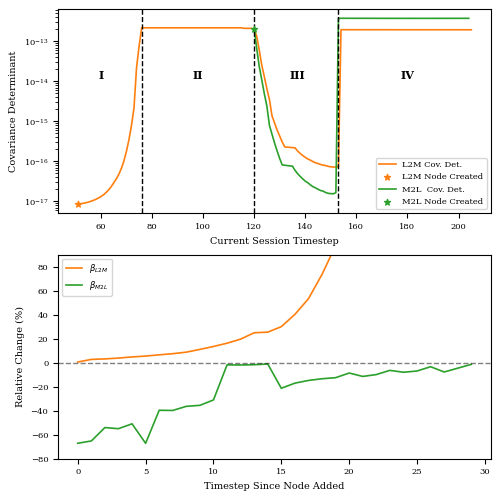

In [10]:
plt.close('Boundary Node Covariance Change Plot')
fig, ax = plt.subplots(2, 1, num='Boundary Node Covariance Change Plot', figsize=(WIDTH_SINGLE, HEIGHT_DOUBLE))
# fig, ax = plt.subplots(2, 1, num='Boundary Node Covariance Change Plot', figsize=(10, 10))
ax.flatten()
[ax1, ax2] = ax
# Determine which keys will actually be plotted
mapStartKey, mapStartDets = list(addToPriorDets.items())[0]

mapEndKey, mapEndDets = list(addToPriorDets.items())[-1]

map_start = gtsam.Symbol(mapStartKey).index()
map_end = gtsam.Symbol(mapEndKey).index()

x_start = np.arange(map_start, map_start+len(mapStartDets))
x_end = np.arange(map_end, map_end+len(mapEndDets))

ax1.plot(x_start, mapStartDets, color="C1", label=r"L2M Cov. Det.")
ax1.scatter(x_start[0], mapStartDets[0], color="C1", s=20, zorder=3, marker='*', label=r"L2M Node Created")

ax1.plot(x_end, mapEndDets, color="C2", label=r"M2L  Cov. Det.")
ax1.scatter(x_end[0], mapEndDets[0], color="C2", s=20, zorder=3, marker='*', label=r"M2L Node Created")

ax1.set_yscale('log')
ax1.legend(loc="lower right")
ax1.set_xlabel("Current Session Timestep")
ax1.set_ylabel("Covariance Determinant")
# ax1.axvline(map_start, color='k', linestyle='--', linewidth=1)
ax1.axvline(76, color='k', linestyle='--', linewidth=1)
ax1.axvline(map_end, color='k', linestyle='--', linewidth=1)
ax1.axvline(153, color='k', linestyle='--', linewidth=1)

# Add roman numeral text at specified x positions
roman_labels = ['I', 'II', 'III', 'IV']
roman_x = [60, 98, 137, 180]
# Choose a reasonable y coordinate near the top of the plotting area
y_roman = np.max(mapStartDets) * 0.75  # You may adjust the multiplier if needed
y_roman = 1e-14

for rx, label in zip(roman_x, roman_labels):
    ax1.text(rx, y_roman, label, fontsize=8, ha='center', va='bottom', fontweight='bold')



duration = 30
mapStartDets = np.asarray(mapStartDets[:24])
# mapStartDets = np.asarray(mapStartDets[:30])
mapEndDets = np.asarray(mapEndDets[:31])

pct_change_start = 100 * np.diff(mapStartDets) / mapStartDets[:-1]
pct_change_end = 100 * np.diff(mapEndDets) / mapEndDets[:-1]

# Determine the combined y-limits to align both y axes
combined_min = min(np.min(pct_change_start), np.min(pct_change_end))
combined_max = max(np.max(pct_change_start), np.max(pct_change_end))

# Plot start key changes
line1, = ax2.plot(pct_change_start, color="C1", label=r"$\beta_{L2M}$")
line2, = ax2.plot(pct_change_end, color="C2", label=r"$\beta_{M2L}$")

# peakidx = np.argmax(pct_change_start)
# ax2.axvline(peakidx, color='k', linestyle='--', linewidth=1)

# Set same y-limits for both axes to align them
ax2.set_ylim(-80, 90)

# Set label colors to match plot colors
ax2.set_ylabel("Relative Change (%)")


ax2.set_xlabel("Timestep Since Node Added")
ax2.axhline(0, linestyle='--', linewidth=1, color="k", alpha=0.5)
# ax2.axhline(10, linestyle=':', linewidth=1, color="tab:gray", alpha=0.5)
# line3 = ax2.axhline(-10, linestyle=':', linewidth=1, color="tab:gray", alpha=0.5, label=r"$10\%$ threshold")

# Legends for both y axes
lines = [line1, line2]
labels = [line.get_label() for line in lines]
ax2.legend(lines, labels, loc="upper left")

plt.tight_layout()
plt.show()

In [13]:
i = 0
while i < len(pct_change_start):
    if i % 4 == 0:
        print(f"Timestep {i}: {pct_change_start[i]:.2f}%")
    i += 1

Timestep 0: 0.49%
Timestep 4: 4.74%
Timestep 8: 8.72%
Timestep 12: 19.54%
Timestep 16: 40.14%
Timestep 20: 127.25%
Timestep 24: 185.88%
Timestep 28: -0.00%


In [22]:
plt.savefig(figure_directory / "Boundary_Node_Covariance_Change_Plot.pdf", format="pdf", dpi=300)#, bbox_inches="tight")

## Timing Plots For Each Decision Policy - Newer College

RELATIVE_COVARIANCE: size = 2185, mean = 6.846 (ms), sd = 6.001
File not found: TWO_STEP_VALIDATION/timeToCalcMetricsAndDecision.txt
INLIER_RMSE: size = 2185, mean = 137.592 (ms), sd = 136.905
INLIER_RATIO: size = 2185, mean = 137.628 (ms), sd = 136.303
OVERLAP: size = 2185, mean = 14.227 (ms), sd = 6.801
DISTANCE: size = 2185, mean = 0.843 (ms), sd = 0.418


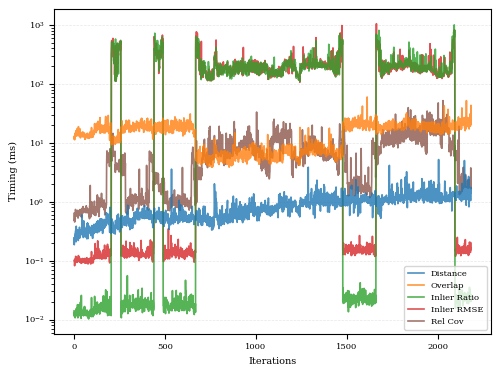

In [12]:
mainDir = Path().home() / "decision_policy_python/results/accuracyEval/nc/exact/post/park__cloister__quad-hard__quad-medium__quad-easy"
secondaryDir = Path().home() / "decision_policy_python/results/twoStepEval2/nc/exact/post/park__cloister__quad-hard__quad-medium__quad-easy"

timing_data: dict[str, np.ndarray] = {}
figName = "Timing Decision Policy"
plt.close(figName)
# plt.figure(figName)
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(WIDTH_SINGLE, HEIGHT_SINGLE), num=figName)
lines = []
for dt in reversed(DecisionType):
    if dt == DecisionType.NONE or dt == DecisionType.TWO_OPTION:
        # print("Skipping None")
        continue
    if dt == DecisionType.TWO_STEP_VALIDATION:
        tmpPath = secondaryDir / dt.name / "timeToCalcMetricsAndDecision.txt"
    else:
        tmpPath = mainDir / dt.name / "timeToCalcMetricsAndDecision.txt"
    if not tmpPath.is_file():
        print(f"File not found: {str(dt.name + "/timeToCalcMetricsAndDecision.txt")}")
        continue

    timing_data[dt.name] = np.loadtxt(tmpPath)
    print(f"{dt.name}: size = {timing_data[dt.name].size}, mean = {np.mean(timing_data[dt.name])*1e3:.3f} (ms), sd = {np.std(timing_data[dt.name]*1e3):.3f}")
    lines += ax.plot(timing_data[dt.name] * 1e3, label=policy_labels[dt.name], color=policy_colors[dt.name], alpha=0.8)


# twoOptionFile = Path("/home/benb/blocklio/python/results/accuracyEval/nc/exact/post2option/park__cloister__quad-hard__quad_medium__quad-easy/TWO_STEP_VALIDATION/timeToCalcMetricsAndDecision.txt")
# twoOptionData = np.loadtxt(twoOptionFile)
# lines += ax.plot(twoOptionData * 1e3, label="Two Option", alpha=0.8)

plt.yscale("log")
plt.xlabel("Iterations")
plt.ylabel("Timing (ms)")
# plt.title("Decision Policy Timing Comparison")
# lines.reverse()
# labels = [line.get_label() for line in lines]
# plt.legend(lines, labels, loc="lower right",)
plt.legend(loc="lower right", reverse=True)

# plt.legend(loc="upper right")
plt.grid(axis='y', linestyle='--')




In [16]:
plt.savefig(figure_directory / "Policy_Timing_Comparison_NC.pdf", format="pdf", dpi=300)#, bbox_inches="tight")

## Timing Plots for Decision - NCLT

RELATIVE_COVARIANCE: size = 6614, mean = 3.793 (ms), sd = 1.585
File not found: TWO_OPTION/timeToCalcMetricsAndDecision.txt
TWO_STEP_VALIDATION: size = 6614, mean = 913.644 (ms), sd = 3054.755
INLIER_RMSE: size = 6614, mean = 0.290 (ms), sd = 7.972
INLIER_RATIO: size = 6614, mean = 0.182 (ms), sd = 6.864
OVERLAP: size = 6614, mean = 12.698 (ms), sd = 3.279
DISTANCE: size = 6614, mean = 1.228 (ms), sd = 0.738
Skipping None


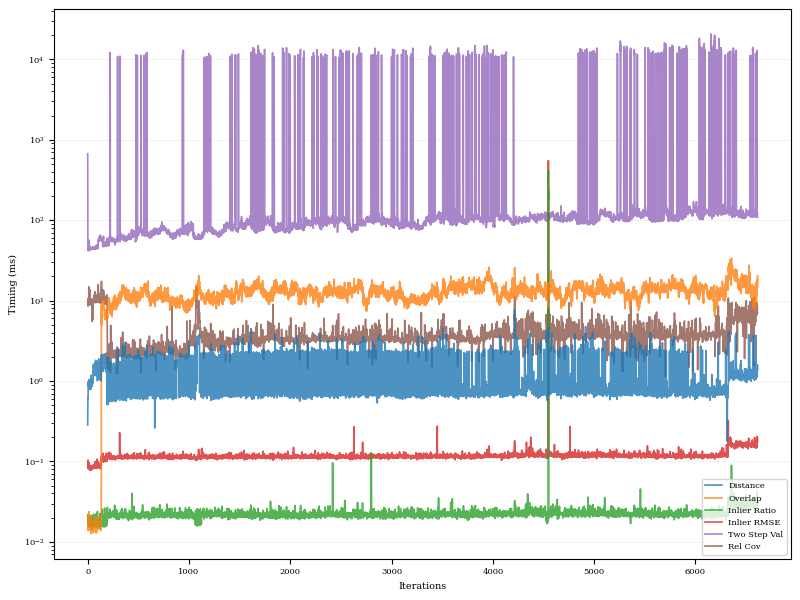

In [21]:
mainDir = Path().home() / "decision_policy_python/results/accuracyEval/nclt/exact/post/2012-01-15__2012-01-08"
secondaryDir = Path().home() / "decision_policy_python/results/twoStepValCorrectTiming/nclt/exact/post/2012-01-15__2012-01-08"

timing_data: dict[str, np.ndarray] = {}
figName = "Timing Decision Policy"
plt.close(figName)
# plt.figure(figName)
# fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(WIDTH_SINGLE, HEIGHT_SINGLE), num=figName)
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 6), num=figName)
lines = []
for dt in reversed(DecisionType):
    if dt == DecisionType.NONE:
    # if not dt == DecisionType.INLIER_RMSE:
        print("Skipping None")
        continue
    tmpPath = mainDir / dt.name / "timeToCalcMetricsAndDecision.txt"
    if not tmpPath.is_file():
        tmpPath = secondaryDir / dt.name / "timeToCalcMetricsAndDecision.txt"
        if not tmpPath.is_file():
            print(f"File not found: {str(dt.name + "/timeToCalcMetricsAndDecision.txt")}")
            continue

    timing_data[dt.name] = np.loadtxt(tmpPath)
    # timing_data[dt.name] = timing_data[dt.name][timing_data[dt.name] <=0.001]
    print(f"{dt.name}: size = {timing_data[dt.name].size}, mean = {np.mean(timing_data[dt.name])*1e3:.3f} (ms), sd = {np.std(timing_data[dt.name]*1e3):.3f}")
    lines += ax.plot(timing_data[dt.name] * 1e3, label=policy_labels[dt.name], color=policy_colors[dt.name], alpha=0.8)


# twoOptionFile = Path("/home/benb/blocklio/python/results/accuracyEval/nc/exact/post2option/park__cloister__quad-hard__quad_medium__quad-easy/TWO_STEP_VALIDATION/timeToCalcMetricsAndDecision.txt")
# twoOptionData = np.loadtxt(twoOptionFile)
# lines += ax.plot(twoOptionData * 1e3, label="Two Option", alpha=0.8)

plt.yscale("log")
plt.xlabel("Iterations")
plt.ylabel("Timing (ms)")
# plt.title("Decision Policy Timing Comparison")
# lines.reverse()
# labels = [line.get_label() for line in lines]
# plt.legend(lines, labels, loc="lower right",)
plt.legend(loc="lower right", reverse=True)

# plt.legend(loc="upper right")
plt.grid(axis='y', linestyle='--')




In [18]:
plt.savefig(figure_directory / "Policy_Timing_Comparison_NCLT.pdf", format="pdf", dpi=300)#, bbox_inches="tight")

## Optimization Timing - NCLT

RELATIVE_COVARIANCE: size = 6614, mean = 74.621 (ms), sd = 20.280
File not found: TWO_OPTION/timeToOptimize.txt
TWO_STEP_VALIDATION: size = 6614, mean = 158.777 (ms), sd = 81.210
INLIER_RMSE: size = 6614, mean = 79.950 (ms), sd = 13.675
INLIER_RATIO: size = 6614, mean = 80.150 (ms), sd = 13.450
OVERLAP: size = 6614, mean = 70.361 (ms), sd = 13.340
DISTANCE: size = 6614, mean = 75.996 (ms), sd = 16.284
NONE: size = 6614, mean = 313.440 (ms), sd = 173.148


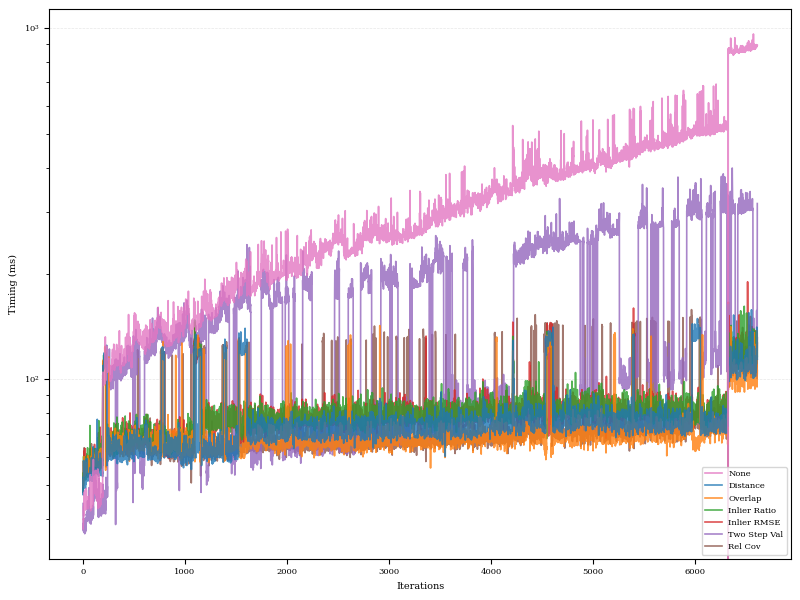

In [27]:
mainDir = Path().home() / "decision_policy_python/results/accuracyEval/nclt/exact/post/2012-01-15__2012-01-08"
secondaryDir = Path().home() / "decision_policy_python/results/twoStepValCorrectTiming/nclt/exact/post/2012-01-15__2012-01-08"

timing_data: dict[str, np.ndarray] = {}
figName = "Timing Decision Policy"
plt.close(figName)
# plt.figure(figName)
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 6), num=figName)
lines = []
for dt in reversed(DecisionType):
    # if dt == DecisionType.NONE:
    #     print("Skipping None")
    #     continue
    tmpPath = mainDir / dt.name / "timeToOptimize.txt"
    if not tmpPath.is_file():
        tmpPath = secondaryDir / dt.name / "timeToOptimize.txt"
        if not tmpPath.is_file():
            print(f"File not found: {str(dt.name + "/timeToOptimize.txt")}")
            continue

    data = np.loadtxt(tmpPath)
    # Replace any Data > 1 with 0
    timing_data[dt.name] = data
    timing_data[dt.name][timing_data[dt.name] > 1] = 0
    print(f"{dt.name}: size = {timing_data[dt.name].size}, mean = {np.mean(timing_data[dt.name])*1e3:.3f} (ms), sd = {np.std(timing_data[dt.name]*1e3):.3f}")
    # Replace any Data > 1 to Nan
    data[data > 1] = np.nan
    timing_data[dt.name] = data
    lines += ax.plot(timing_data[dt.name] * 1e3, label=policy_labels[dt.name], color=policy_colors[dt.name], alpha=0.8)


# twoOptionFile = Path("/home/benb/blocklio/python/results/accuracyEval/nc/exact/post2option/park__cloister__quad-hard__quad_medium__quad-easy/TWO_STEP_VALIDATION/timeToCalcMetricsAndDecision.txt")
# twoOptionData = np.loadtxt(twoOptionFile)
# lines += ax.plot(twoOptionData * 1e3, label="Two Option", alpha=0.8)

plt.yscale("log")
plt.xlabel("Iterations")
plt.ylabel("Timing (ms)")
# plt.title("Decision Policy Timing Comparison")
# lines.reverse()
# labels = [line.get_label() for line in lines]
# plt.legend(lines, labels, loc="lower right",)
plt.legend(loc="lower right", reverse=True)

# plt.legend(loc="upper right")
plt.grid(axis='y', linestyle='--')


